# EDA

## 1. Setup dan Load Data

In [1]:
import pandas as pd

pd.set_option('display.max_columns', None)

df = pd.read_csv('Raw-Final-Rumah.csv')
print("Bentuk Dataset : ", df.shape)
print("5 data teratas : ")
display(df.head())
print("Informasi tipe data dan jumlah data tiap kolomnya :")
df.info()

Bentuk Dataset :  (40200, 8)
5 data teratas : 


,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
0,"2,5 Miliar",4,3,10,LT : 438 m²,LB : 110 m²,Tapos,129
1,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129
2,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Cipayung,129
3,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Rangkapanjaya,129
4,385 Juta,3,2,1,LT : 50 m²,LB : 60 m²,Pancoran Mas,129


Informasi tipe data dan jumlah data tiap kolomnya :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Harga          40200 non-null  object
 1   Kamar Tidur    40191 non-null  object
 2   Kamar Mandi    35797 non-null  object
 3   Garasi         35011 non-null  object
 4   Luas Tanah     32501 non-null  object
 5   Luas Bangunan  24598 non-null  object
 6   Kecamatan      40200 non-null  object
 7   Page           40200 non-null  int64 
dtypes: int64(1), object(7)
memory usage: 2.5+ MB


Langkah pertama cukup sederhana: memuat dataset dan melihat bentuk aslinya sebelum disentuh apa pun.

Hasilnya 40.200 baris dan 8 kolom, sesuai deskripsi di soal. Hanya `Page` yang bertipe angka. Tujuh kolom lainnya terbaca sebagai teks (`object`), termasuk `Harga`, `Luas Tanah`, dan `Luas Bangunan`. Isinya masih string bersatuan seperti "2,5 Miliar" atau "LT : 438 m²", jadi semuanya harus diparsing dulu sebelum bisa dipakai model.

`info()` juga sudah menunjukkan jumlah data kosong. Luas Bangunan paling banyak (15.602 baris), disusul Luas Tanah (7.699), Garasi (5.189), Kamar Mandi (4.403), dan Kamar Tidur (9). `Harga` dan `Kecamatan` tidak ada yang kosong. Angka ini belum final, karena sebagian yang tampak kosong bisa jadi hanya salah kolom. Itu yang kita telusuri di tahap EDA.

Library lain (matplotlib, seaborn, scikit-learn) sengaja belum diimpor. Masing-masing akan diimpor di cell yang memakainya.

## 2. Profil Awal Data

In [2]:
profil = pd.DataFrame({
    'missing': df.isna().sum(),
    'missing_%': (df.isna().mean() * 100).round(2),
    'unik': df.nunique(),
})
display(profil)

print('Duplikat (semua kolom)  :', df.duplicated().sum())
print('Duplikat (tanpa Page)   :', df.drop(columns='Page').duplicated().sum())

,missing,missing_%,unik
Harga,0,0.00,2432
Kamar Tidur,9,0.02,1322
Kamar Mandi,4403,10.95,688
Garasi,5189,12.91,1085
Luas Tanah,7699,19.15,1327
Luas Bangunan,15602,38.81,557
Kecamatan,0,0.00,38
Page,0,0.00,2010


Duplikat (semua kolom)  : 1525
Duplikat (tanpa Page)   : 9478


Sebelum membersihkan apa pun, saya mau tahu dulu seberapa berantakan datanya. Tiga hal yang dicek: data kosong, jumlah nilai unik, dan duplikat.

**Data kosong.** Luas Bangunan paling parah, hampir 39% barisnya kosong (15.602). Luas Tanah 19%, Garasi 13%, Kamar Mandi 11%, dan Kamar Tidur hanya 9 baris. Kolom Harga dan Kecamatan lengkap. Dengan proporsi sebesar ini, membuang semua baris yang kosong jelas bukan pilihan, karena data kita akan menyusut drastis.

**Nilai unik.** Ada yang janggal di sini. Kamar Tidur punya 1.322 nilai unik, padahal jumlah kamar tidur seharusnya hanya belasan angka. Kamar Mandi (688) dan Garasi (1.085) juga terlalu banyak. Ini tanda kuat bahwa kolom-kolom tersebut berisi data yang salah tempat, misalnya luas tanah atau luas bangunan yang nyasar ke kolom jumlah kamar. Dugaan ini akan kita buktikan di langkah audit pola isi kolom.

**Duplikat.** Ada 1.525 baris yang identik di semua kolom. Namun kalau kolom `Page` diabaikan, jumlahnya melonjak jadi 9.478 baris (sekitar 24%). Artinya banyak listing yang sama muncul di halaman scraping yang berbeda. `Page` hanya penanda halaman, jadi duplikat versi kedua inilah yang lebih mewakili kondisi sebenarnya. Cara menanganinya kita putuskan di tahap preprocessing.

Satu hal yang belum bisa disimpulkan dari tabel ini: kolom `Kecamatan` hanya punya 38 nilai unik, tetapi isinya belum tentu seragam levelnya. Itu juga kita periksa nanti.

## 3. Audit Pola Isi Kolom

In [3]:
kolom = ['Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']
tipe = lambda s: s.str.extract(r'^(LT|LB)')[0].fillna('angka').where(s.notna(), 'kosong')

print('Tipe isi per kolom:')
display(pd.DataFrame({c: tipe(df[c]).value_counts() for c in kolom}).fillna(0).astype(int))

print('Pola format Harga:')
display(df['Harga'].str.replace(r'[\d.,]+', '#', regex=True).value_counts())

print('Nilai Kecamatan:')
display(df['Kecamatan'].value_counts())

Tipe isi per kolom:


,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan
0,,,,,
LB,90,782,2498,7901,24598
LT,4851,1379,7906,24600,0
angka,35250,33636,24607,0,0
kosong,9,4403,5189,7699,15602


Pola format Harga:


,count
Harga,
# Miliar,20262
# Juta,13872
# Miliar Total,5083
# Juta Total,807
# Triliun Total,59
# Juta /m²,44
Hubungi Agen,41
# Ribu,12
# Miliar /m²,11


Nilai Kecamatan:


,count
Kecamatan,
Cinere,8602
Sawangan,4650
Cimanggis,2978
Pancoran Mas,2386
Cilodong,1974
Beji,1893
Sukmajaya,1677
Depok I,1444
Limo,1433


Di langkah ini saya tidak melihat angkanya, tapi *bentuk* isinya. Angka diganti `#` supaya yang kelihatan hanya polanya.

**Kolom bergeser ke kiri.** Tabel pertama membuktikan dugaan di langkah 2. `Luas Bangunan` isinya benar semua (hanya "LB" atau kosong). Tapi kolom lain bercampur: `Kamar Tidur` berisi "LT" di 4.851 baris, `Garasi` berisi "LT" di 7.906 baris dan "LB" di 2.498 baris, dan `Luas Tanah` berisi "LB" di 7.901 baris. Kalau dilihat per baris, polanya konsisten: isi listing dirapatkan ke kiri. Rumah yang tidak punya garasi tidak meninggalkan sel kosong di kolom `Garasi`. Luas tanahnya malah menempati kolom itu, dan luas bangunan menggeser ke `Luas Tanah`. Jadi ini bukan kolom yang "tertukar" secara acak, melainkan pergeseran, dan karena itu bisa diperbaiki secara sistematis di preprocessing.

Ada dua detail yang perlu diingat saat parsing. Pertama, penulisan label beda: "LT:409 m²" (tanpa spasi) di tiga kolom pertama, tapi "LT : 438 m²" (pakai spasi) di kolom luas. Kedua, angka murni di `Kamar Tidur`, `Kamar Mandi`, dan `Garasi` tidak bisa langsung dipastikan milik kolom mana kalau ada yang hilang. Itu yang paling rumit dan kita pikirkan di preprocessing.

**Format Harga.** Ada 12 pola. Sebagian hanya beda cara penulisan dan mudah dibereskan: satuan Miliar dan Juta, dengan atau tanpa kata "Total", serta koma desimal gaya Indonesia ("2,5"). Sisanya butuh keputusan: harga "/m²" (55 baris) dan "/ha" (1 baris) adalah harga per satuan luas, bukan harga rumah; "Hubungi Agen" (41 baris) tidak punya harga sama sekali; satuan "Ribu" (13 baris) mencurigakan untuk harga rumah; dan "Triliun" (66 baris) kita pertahankan dulu, nilainya kita periksa di EDA untuk memisahkan yang wajar dan yang salah input.

**Kecamatan.** Level isinya campur aduk. Depok hanya punya 11 kecamatan resmi (Beji, Bojong Sari, Cilodong, Cimanggis, Cinere, Cipayung, Limo, Pancoran Mas, Sawangan, Sukmajaya, Tapos). Sisanya dari 38 nilai ini adalah kelurahan, kawasan, atau perumahan, seperti Margonda, Cibubur, Grand Depok City, dan Studio Alam. Sebarannya juga timpang: Cinere punya 8.602 baris, sedangkan Sumur Batu hanya 1.

## 4. Tabel Temuan Kualitas Data

In [4]:
ada = lambda p: df[kolom].apply(lambda s: s.str.match(p, na=False)).any(axis=1)
bergeser = df[kolom[:3]].apply(lambda s: s.str.match('L', na=False)).any(axis=1) | df['Luas Tanah'].str.startswith('LB', na=False)
resmi = ['Beji', 'Bojong Sari', 'Cilodong', 'Cimanggis', 'Cinere', 'Cipayung',
         'Limo', 'Pancoran Mas', 'Sawangan', 'Sukmajaya', 'Tapos']
jml_kec = df['Kecamatan'].map(df['Kecamatan'].value_counts())
h = df['Harga']

temuan = pd.DataFrame([
    ('Isi kolom bergeser ke kiri', bergeser.sum(),
     'Scraping merapatkan atribut yang ada ke kiri saat ada atribut yang tidak dicantumkan'),
    ('Missing value tampak (minimal 1 kolom kosong)', df[kolom].isna().any(axis=1).sum(),
     'Sebagian semu akibat pergeseran, sebagian atribut memang tidak dicantumkan penjual'),
    ('Luas tanah benar-benar tidak ada', (~ada('LT')).sum(),
     'Tidak ada "LT" di kolom mana pun, penjual tidak mencantumkan'),
    ('Luas bangunan benar-benar tidak ada', (~ada('LB')).sum(),
     'Tidak ada "LB" di kolom mana pun, kemungkinan kavling atau tanah kosong'),
    ('Duplikat identik', df.duplicated().sum(),
     'Baris yang sama terambil dua kali pada halaman yang sama'),
    ('Duplikat tanpa Page', df.drop(columns='Page').duplicated().sum(),
     'Listing yang sama muncul di halaman scraping berbeda'),
    ('Duplikat tanpa Page dan Kecamatan', df.drop(columns=['Page', 'Kecamatan']).duplicated().sum(),
     'Listing yang sama diberi label Kecamatan berbeda'),
    ('Harga per m² atau per ha', h.str.contains('/m²|/ha').sum(),
     'Harga ditulis per satuan luas, bukan harga total rumah'),
    ('Harga "Hubungi Agen"', (h == 'Hubungi Agen').sum(),
     'Harga tidak dipublikasikan oleh penjual'),
    ('Harga satuan Ribu', h.str.contains('Ribu').sum(),
     'Kemungkinan salah input, nilainya tidak wajar untuk harga rumah'),
    ('Harga satuan Triliun', h.str.contains('Triliun').sum(),
     'Bisa valid (kawasan premium atau lahan sangat luas), bisa juga salah input'),
    ('Kecamatan bukan kecamatan resmi', (~df['Kecamatan'].isin(resmi)).sum(),
     'Level wilayah campur: ada kelurahan, kawasan, dan perumahan'),
    ('Kecamatan sangat jarang (<50 baris)', (jml_kec < 50).sum(),
     'Terlalu sedikit data untuk dipelajari model'),
], columns=['Masalah', 'Jumlah baris', 'Kemungkinan penyebab'])

display(temuan)

,Masalah,Jumlah baris,Kemungkinan penyebab
0,Isi kolom bergeser ke kiri,15580,Scraping merapatkan atribut yang ada ke kiri s...
1,Missing value tampak (minimal 1 kolom kosong),15602,"Sebagian semu akibat pergeseran, sebagian atri..."
2,Luas tanah benar-benar tidak ada,1464,"Tidak ada ""LT"" di kolom mana pun, penjual tida..."
3,Luas bangunan benar-benar tidak ada,4331,"Tidak ada ""LB"" di kolom mana pun, kemungkinan ..."
4,Duplikat identik,1525,Baris yang sama terambil dua kali pada halaman...
5,Duplikat tanpa Page,9478,Listing yang sama muncul di halaman scraping b...
6,Duplikat tanpa Page dan Kecamatan,12331,Listing yang sama diberi label Kecamatan berbeda
7,Harga per m² atau per ha,56,"Harga ditulis per satuan luas, bukan harga tot..."
8,"Harga ""Hubungi Agen""",41,Harga tidak dipublikasikan oleh penjual
9,Harga satuan Ribu,13,"Kemungkinan salah input, nilainya tidak wajar ..."


Tabel ini merangkum semua masalah yang sudah ketemu di langkah 2 dan 3, ditambah beberapa yang baru muncul saat dihitung ulang. Beberapa temuan mengubah cara saya membaca data.

**Missing value ternyata banyak yang semu.** Di tabel mentah, Luas Tanah tampak kosong di 7.699 baris. Tapi setelah melihat semua kolom, hanya 1.464 baris yang benar-benar tidak punya luas tanah. Sisanya sebenarnya ada, hanya nyasar ke kolom di sebelah kirinya. Pola yang sama berlaku untuk luas bangunan (15.602 tampak kosong, 4.331 yang benar-benar tidak ada). Jadi memperbaiki pergeseran kolom harus dikerjakan sebelum menangani missing value, kalau tidak kita akan mengisi nilai yang sebenarnya sudah ada.

**Listing tanpa luas bangunan bukan rumah biasa.** Dari 4.331 listing itu, hampir semuanya hanya punya luas tanah dan tidak punya jumlah kamar sama sekali. Ini kemungkinan besar kavling atau tanah kosong, dan harganya mengikuti logika yang berbeda dari rumah. Keputusan apakah baris ini dipertahankan akan kita ambil setelah melihat distribusi harganya.

**Duplikat lebih parah dari yang terlihat.** Duplikat identik hanya 1.525 baris. Kalau `Page` diabaikan naik jadi 9.478, dan kalau `Kecamatan` ikut diabaikan jadi 12.331 baris (sekitar 31% data). Artinya listing yang sama sering diberi label kecamatan berbeda, jadi satu rumah bisa tercatat di dua wilayah. Kalau tidak dibereskan, model akan melihat rumah yang sama berkali-kali dan bisa membuat evaluasi terlalu optimis, karena baris yang sama bisa jatuh ke data latih dan data uji sekaligus.

**Harga.** Harga per m²/ha (56 baris) dan "Hubungi Agen" (41 baris) tidak bisa dipakai sebagai target apa adanya. Satuan Ribu (13 baris) mencurigakan. Satuan Triliun (66 baris) kita pertahankan dulu dan diuji di EDA, apakah nilainya masih masuk akal dibanding luas tanahnya.

**Kecamatan.** Sebanyak 11.544 baris (sekitar 29%) berisi nama yang bukan kecamatan resmi, dan 5 nilai muncul kurang dari 50 kali. Ini perlu disederhanakan sebelum diubah jadi fitur kategori.

Pekerjaan perbaikannya semua ada di tahap preprocessing. Tabel ini jadi daftar pekerjaannya.


---
# Preprocessing

## 5. Membuat Salinan Data untuk EDA (`df_eda`)

In [5]:
satuan = {'Triliun': 1e12, 'Miliar': 1e9, 'Juta': 1e6, 'Ribu': 1e3}
harga = df['Harga'].str.extract(r'([\d,]+)\s*(Triliun|Miliar|Juta|Ribu)')
teks = df[kolom].fillna('').agg(' '.join, axis=1)  # gabung 5 kolom agar LT/LB bisa dicari di mana pun

df_eda = pd.DataFrame({
    'Harga': harga[0].str.replace(',', '.').astype(float) * harga[1].map(satuan),
    'Harga per luas': df['Harga'].str.contains('/m²|/ha'),
    'Kamar Tidur': pd.to_numeric(df['Kamar Tidur'], errors='coerce'),
    'Kamar Mandi': pd.to_numeric(df['Kamar Mandi'], errors='coerce'),
    'Garasi': pd.to_numeric(df['Garasi'], errors='coerce'),
    'Luas Tanah': teks.str.extract(r'LT\s*:\s*(\d+)')[0].astype(float),
    'Luas Bangunan': teks.str.extract(r'LB\s*:\s*(\d+)')[0].astype(float),
    'Kecamatan': df['Kecamatan'],
})

# cek: jumlah data terisi harus sama dengan hasil audit di tabel temuan
assert df_eda['Harga'].notna().sum() == 40200 - 41
assert df_eda['Luas Tanah'].notna().sum() == 40200 - 1464
assert df_eda['Luas Bangunan'].notna().sum() == 40200 - 4331

df_eda.info()
display(df_eda.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40200 entries, 0 to 40199
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Harga           40159 non-null  float64
 1   Harga per luas  40200 non-null  bool   
 2   Kamar Tidur     35250 non-null  float64
 3   Kamar Mandi     33636 non-null  float64
 4   Garasi          24607 non-null  float64
 5   Luas Tanah      38736 non-null  float64
 6   Luas Bangunan   35869 non-null  float64
 7   Kecamatan       40200 non-null  object 
dtypes: bool(1), float64(6), object(1)
memory usage: 2.2+ MB


,count,mean,std,min,25%,50%,75%,max
Harga,40159.0,1.939820e+11,1.519224e+13,3500.0,760000000.0,1.500000e+09,3.300000e+09,1.902800e+15
Kamar Tidur,35250.0,3.668652e+00,4.719539e+00,1.0,2.0,3.000000e+00,4.000000e+00,2.840000e+02
Kamar Mandi,33636.0,2.749049e+00,3.678546e+00,1.0,1.0,2.000000e+00,3.000000e+00,1.800000e+02
Garasi,24607.0,1.590442e+00,1.396581e+00,1.0,1.0,1.000000e+00,2.000000e+00,3.000000e+01
Luas Tanah,38736.0,3.714144e+04,4.519610e+06,1.0,72.0,1.150000e+02,2.850000e+02,8.188011e+08
Luas Bangunan,35869.0,2.586380e+04,4.355443e+06,1.0,60.0,1.000000e+02,2.000000e+02,8.188011e+08


Data mentah `df` sengaja tidak diubah. Semua perbaikan dilakukan di salinan bernama `df_eda`, supaya direct modeling nanti benar-benar jalan di data sebelum preprocessing.

**Harga** diambil dengan regex: angka di depan dan satuan (Triliun, Miliar, Juta, Ribu) di belakang. Koma desimal ("2,5") diganti titik, lalu dikalikan nilai satuannya sehingga hasilnya rupiah penuh. Kata "Total" otomatis terabaikan. "Hubungi Agen" tidak punya angka, jadi menjadi kosong (41 baris). Harga "/m²" dan "/ha" (56 baris) tetap dihitung angkanya, tapi ditandai di kolom `Harga per luas` karena angka itu belum berupa harga total rumah. Baris "Juta /m²" nanti dikalikan luas tanah di tahap preprocessing, sedangkan sisanya dibuang karena hasil konversinya tidak masuk akal.

**Luas Tanah dan Luas Bangunan** diperbaiki dengan cara menggabungkan kelima kolom jadi satu teks per baris, lalu mencari "LT : angka" dan "LB : angka" di mana pun posisinya. Dengan cara ini pergeseran kolom otomatis teratasi, tanpa perlu menebak baris mana yang bergeser.

**Kamar Tidur, Kamar Mandi, Garasi** hanya diubah ke angka. Teks "LT:..." atau "LB:..." di kolom ini menjadi kosong karena sudah diambil ke kolom luas. Angka murninya saya biarkan di kolom asalnya. Ini asumsi, tapi didukung data: angka murni selalu menempel di kiri (pola 111, 110, 100, atau 000), dan angka kedua pada baris yang hanya punya dua angka sebaran nilainya mirip Kamar Mandi, bukan Garasi. Asumsi ini akan saya sebut lagi saat preprocessing.

Hasilnya cocok dengan tabel temuan, dan tiga `assert` memastikan hal itu. Ada juga beberapa temuan baru yang jelas bermasalah: harga terkecil hanya Rp 3.500, harga terbesar hampir Rp 2 kuadriliun, luas tanah maksimum 818 juta m², Kamar Tidur sampai 284, dan Kamar Mandi sampai 180. Semua ini kita bahas di visualisasi dan insight berikutnya. Garasi minimal bernilai 1, tidak pernah 0, yang artinya rumah tanpa garasi kemungkinan besar dicatat kosong. Itu bahan keputusan untuk preprocessing.

## 6. Visualisasi: Distribusi Harga

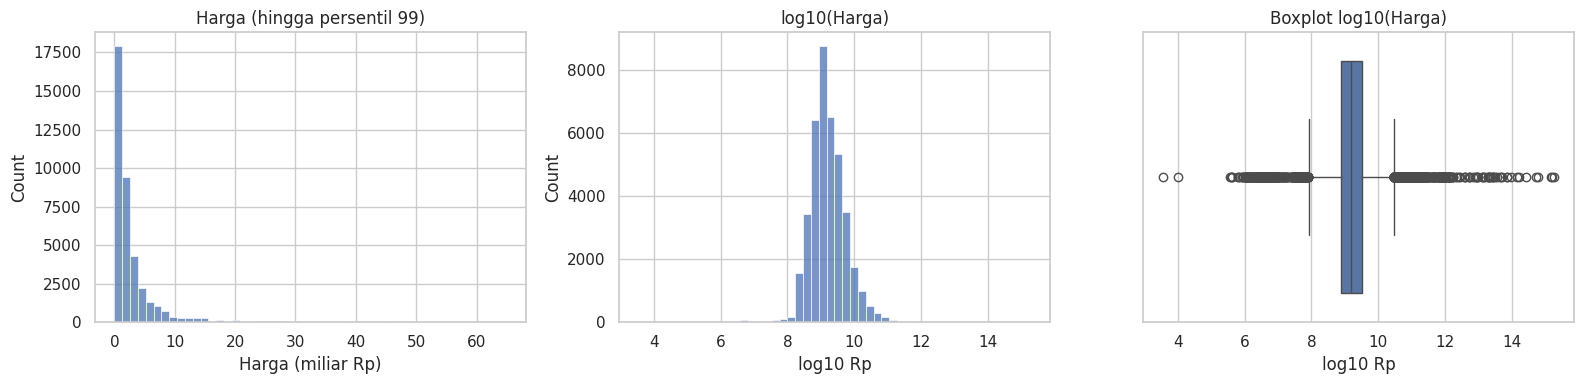

Jumlah data: 40103
Skewness: asli 104.8 | log 0.47


In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
h = df_eda.loc[~df_eda['Harga per luas'], 'Harga'].dropna()  # hanya harga total rumah

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(h[h <= h.quantile(.99)] / 1e9, bins=50, ax=ax[0])
ax[0].set(title='Harga (hingga persentil 99)', xlabel='Harga (miliar Rp)')
sns.histplot(np.log10(h), bins=50, ax=ax[1])
ax[1].set(title='log10(Harga)', xlabel='log10 Rp')
sns.boxplot(x=np.log10(h), ax=ax[2])
ax[2].set(title='Boxplot log10(Harga)', xlabel='log10 Rp')
plt.tight_layout()
plt.show()

print(f'Jumlah data: {len(h)}')
print(f'Skewness: asli {h.skew():.1f} | log {np.log10(h).skew():.2f}')

Grafik ini memakai 40.103 baris. Harga "/m²", "/ha", dan "Hubungi Agen" dikeluarkan karena bukan harga total rumah.

**Grafik kiri** menunjukkan distribusi harga asli, dan bentuknya miring tajam ke kanan. Sebagian besar rumah ada di bawah beberapa miliar, tapi ekornya panjang sekali. Grafik ini saya potong di persentil 99 (sekitar Rp 65 miliar). Tanpa pemotongan, semua batang menumpuk di satu sisi dan terlihat seperti satu garis, karena nilai terbesarnya mencapai 1,9 kuadriliun. Skewness-nya 104,8, jauh di atas 0 yang berarti simetris.

**Grafik tengah** memakai skala log10. Bentuknya jadi mendekati lonceng dengan puncak di sekitar 10⁹ (Rp 1 miliar), dan skewness turun ke 0,47. Di sisi kiri ada gundukan kecil di kisaran Rp 3 sampai 10 juta. Harga segitu terlalu murah untuk sebuah rumah, jadi kemungkinan itu harga sewa atau salah satuan.

**Grafik kanan** (boxplot) menunjukkan ribuan titik di luar kotak, baik di sisi murah maupun mahal. Kalau kita membuang semua yang lewat batas IQR, data yang terbuang akan sangat banyak, termasuk rumah mahal yang sebenarnya valid. Jadi aturan IQR saja tidak cukup untuk membedakan nilai ekstrem yang valid dari salah input. Kita butuh pembanding lain, misalnya harga per m² tanah, dan itu dibahas setelah ini.

Satu hal yang sudah jelas: skala log membuat target jauh lebih mudah dipelajari model. Itu bahan insight untuk keputusan transformasi target di preprocessing.

Perlu dibedakan dari scaling. `StandardScaler` hanya menggeser dan mengecilkan skala data, sedangkan bentuk distribusinya tetap (skewness Harga setelah distandardisasi masih sama seperti sebelumnya). Yang mengubah bentuk adalah transformasi log. Karena masalah di target adalah kemiringan dan bukan rentang angka, log yang dipakai untuk Harga. Scaling untuk fitur akan dipertimbangkan per model di tahap preprocessing.

## 7. Visualisasi: Harga, Luas, dan Jenis Listing (Rumah vs Kavling)

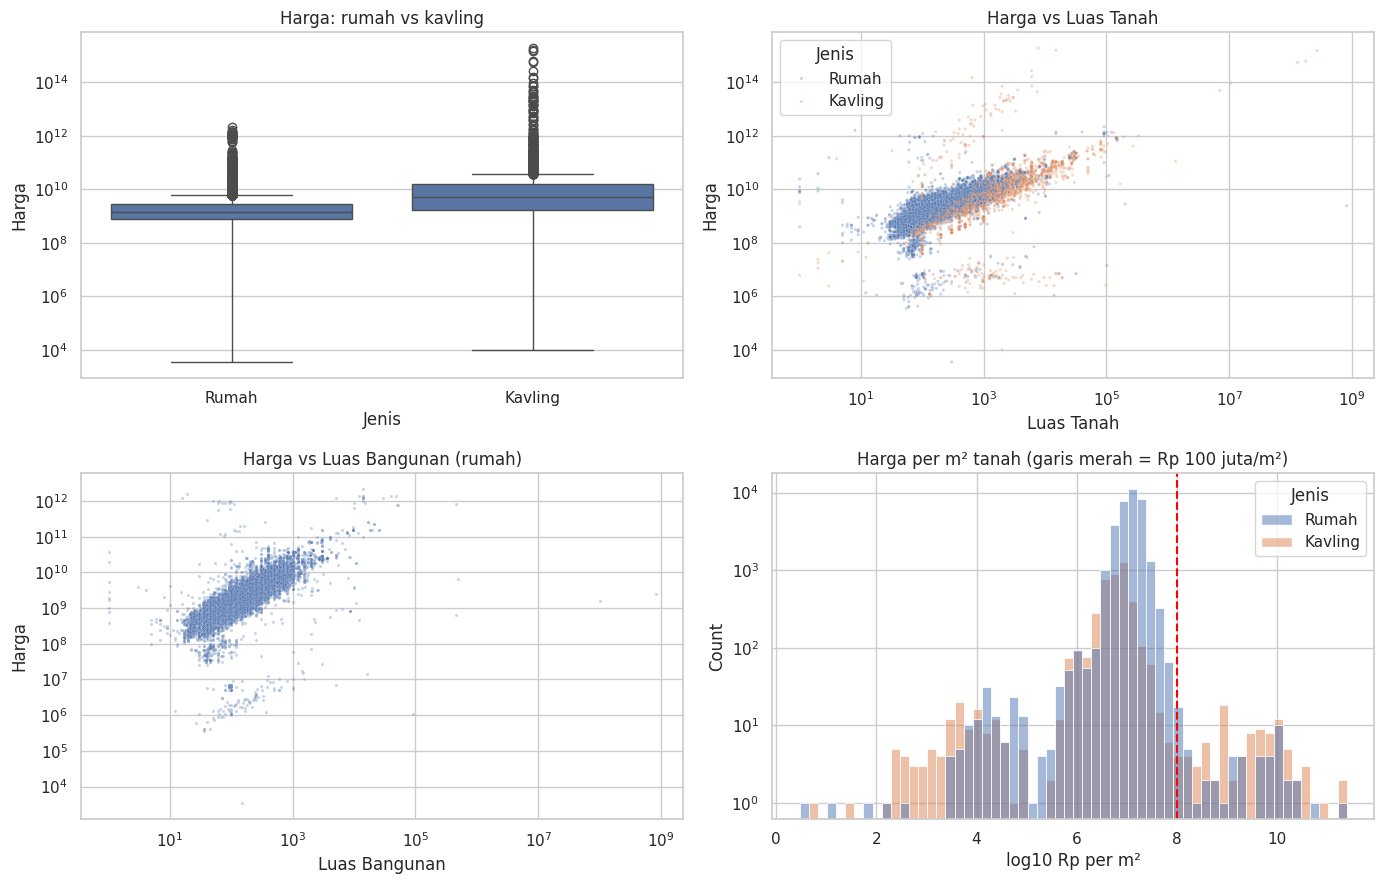

,baris,median_harga_miliar,p95_harga_miliar,median_per_m2_juta
Jenis,,,,
Kavling,4287,5.25,98.7,6.39
Rumah,35816,1.35,9.0,12.28


Harga per m² tanah,< Rp 100 rb/m²,di antaranya,> Rp 100 jt/m²
Jenis,,,
Kavling,116,4060,93
Rumah,122,34198,52


Harga >= 1 triliun,False,True
Jenis,,
Kavling,4234,53
Rumah,35803,13


In [7]:
d = df_eda[~df_eda['Harga per luas']].dropna(subset=['Harga']).copy()
d['Jenis'] = np.where(d['Luas Bangunan'].isna(), 'Kavling', 'Rumah')
d['Harga per m² tanah'] = d['Harga'] / d['Luas Tanah']

fig, ax = plt.subplots(2, 2, figsize=(14, 9))
sns.boxplot(data=d, x='Jenis', y='Harga', ax=ax[0, 0])
ax[0, 0].set(yscale='log', title='Harga: rumah vs kavling')
sns.scatterplot(data=d, x='Luas Tanah', y='Harga', hue='Jenis', s=5, alpha=.3, ax=ax[0, 1])
ax[0, 1].set(xscale='log', yscale='log', title='Harga vs Luas Tanah')
sns.scatterplot(data=d[d['Jenis'] == 'Rumah'], x='Luas Bangunan', y='Harga', s=5, alpha=.3, ax=ax[1, 0])
ax[1, 0].set(xscale='log', yscale='log', title='Harga vs Luas Bangunan (rumah)')
sns.histplot(x=np.log10(d['Harga per m² tanah']), hue=d['Jenis'], bins=60, ax=ax[1, 1])
ax[1, 1].axvline(8, color='red', ls='--')
ax[1, 1].set(yscale='log', title='Harga per m² tanah (garis merah = Rp 100 juta/m²)', xlabel='log10 Rp per m²')
plt.tight_layout()
plt.show()

display(d.groupby('Jenis').agg(
    baris=('Harga', 'size'),
    median_harga_miliar=('Harga', lambda s: s.median() / 1e9),
    p95_harga_miliar=('Harga', lambda s: s.quantile(.95) / 1e9),
    median_per_m2_juta=('Harga per m² tanah', lambda s: s.median() / 1e6),
).round(2))

per_m2 = pd.cut(d['Harga per m² tanah'], [0, 1e5, 1e8, np.inf],
                labels=['< Rp 100 rb/m²', 'di antaranya', '> Rp 100 jt/m²'])
display(pd.crosstab(d['Jenis'], per_m2))
display(pd.crosstab(d['Jenis'], d['Harga'] >= 1e12, colnames=['Harga >= 1 triliun']))

Grafik ini memakai 40.103 listing yang punya harga total. Listing dibagi dua: **rumah** (punya luas bangunan) dan **kavling** (tidak punya luas bangunan). Skala log dipakai di hampir semua sumbu karena harga dan luasnya sama-sama miring ke kanan.

**Rumah vs kavling (kiri atas).** Keduanya jelas berbeda. Median harga kavling Rp 5,25 miliar, sedangkan rumah Rp 1,35 miliar. Di persentil 95 selisihnya lebih jauh lagi: Rp 98,7 miliar untuk kavling, Rp 9 miliar untuk rumah. Kavling hanya 4.287 baris, tapi sebarannya jauh lebih lebar dan hampir semua harga Triliun ada di sana (53 dari 66 baris).

**Harga vs luas tanah (kanan atas).** Di skala log titik-titiknya membentuk jalur miring yang rapat: makin luas tanah, makin mahal. Rumah dan kavling berada di jalur yang sama, hanya kavling menjangkau luas yang lebih besar. Yang menarik ada titik-titik yang jauh dari jalur itu, yaitu gerombolan mendatar di sekitar Rp 1 sampai 10 juta (harga tidak ikut naik walau tanah makin luas) dan titik-titik di atas Rp 1 triliun. Keduanya terpisah jelas dari jalur utama, jadi bukan sekadar ujung distribusi yang wajar. Ini ciri salah input.

**Harga vs luas bangunan (kiri bawah).** Polanya sama: jalur miring yang rapat dengan beberapa titik menyimpang di bagian atas dan bawah.

**Harga per m² tanah (kanan bawah).** Sumbu vertikalnya saya buat log agar ekor-ekornya kelihatan. Sebagian besar listing berkumpul di kisaran Rp 1 sampai 30 juta per m². Di kedua sisi ada ekor tipis: 238 baris di bawah Rp 100 ribu per m² dan 145 baris di atas Rp 100 juta per m². Karena badan data dan ekornya terpisah jelas, harga per m² tanah bisa dipakai sebagai alat untuk membedakan nilai ekstrem yang valid dari salah input, dengan batas yang bisa dipertanggungjawabkan.

Dari tabel ringkasan, median harga per m² tanah kavling (Rp 6,4 juta) lebih rendah dari rumah (Rp 12,3 juta). Wajar, karena harga rumah sudah termasuk bangunan di atasnya.

## 8. Visualisasi: Harga vs Kamar, Garasi, dan Kecamatan

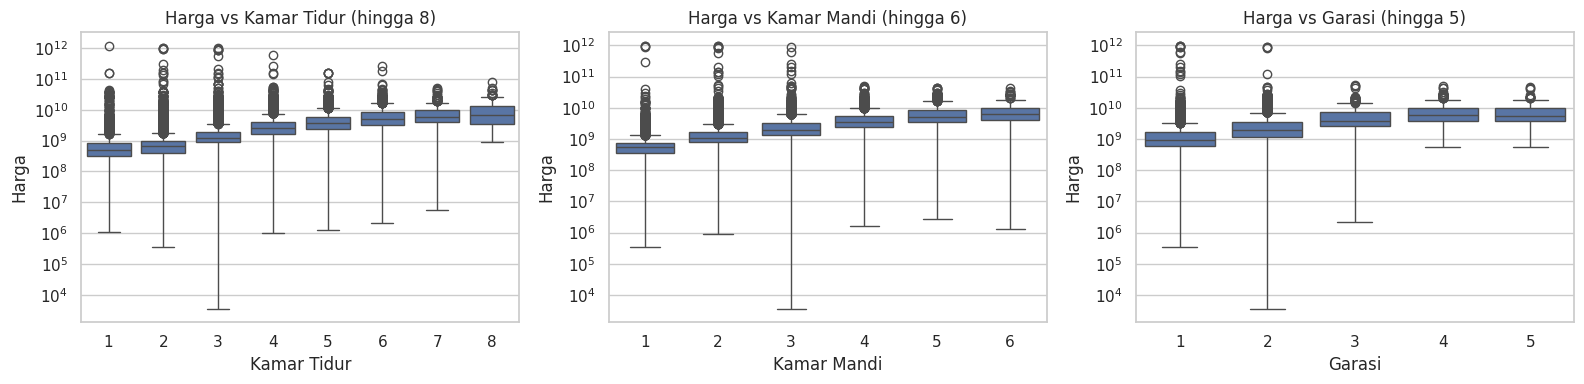

Di luar rentang grafik: {'Kamar Tidur': 839, 'Kamar Mandi': 895, 'Garasi': 399}


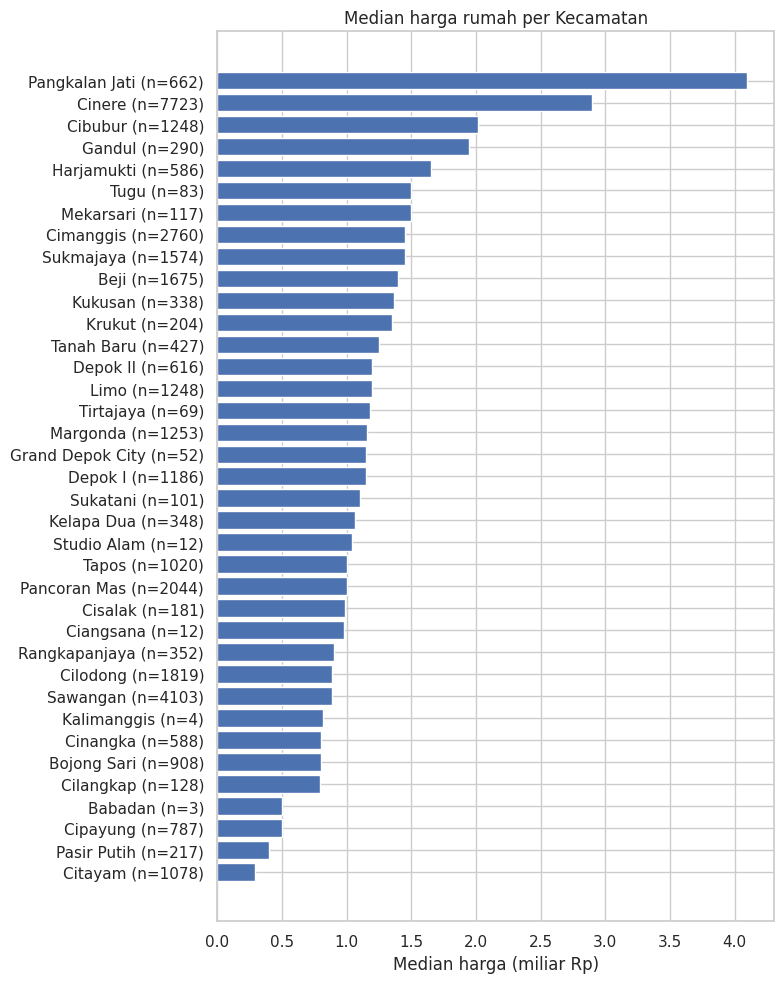

In [8]:
rumah = d[d['Jenis'] == 'Rumah']  # kavling tidak punya info kamar
batas = {'Kamar Tidur': 8, 'Kamar Mandi': 6, 'Garasi': 5}

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (kol, maks) in zip(ax, batas.items()):
    s = rumah[rumah[kol] <= maks]
    sns.boxplot(x=s[kol].astype(int), y=s['Harga'], ax=a)
    a.set(yscale='log', title=f'Harga vs {kol} (hingga {maks})')
plt.tight_layout()
plt.show()
print('Di luar rentang grafik:', {k: int((rumah[k] > m).sum()) for k, m in batas.items()})

kec = rumah.groupby('Kecamatan')['Harga'].agg(['median', 'size']).sort_values('median')
plt.figure(figsize=(8, 10))
plt.barh(kec.index + ' (n=' + kec['size'].astype(str) + ')', kec['median'] / 1e9)
plt.xlabel('Median harga (miliar Rp)')
plt.title('Median harga rumah per Kecamatan')
plt.tight_layout()
plt.show()

Grafik di langkah ini hanya memakai rumah (35.816 baris), karena kavling tidak punya informasi kamar.

**Kamar tidur, kamar mandi, dan garasi.** Ketiganya punya pola yang sama: makin banyak, makin mahal. Median harga rumah dengan 1 kamar tidur sekitar Rp 0,5 miliar, 4 kamar tidur Rp 2,6 miliar, dan 8 kamar tidur Rp 6,7 miliar. Kamar mandi mirip: dari Rp 0,55 miliar untuk 1 kamar mandi sampai Rp 6,5 miliar untuk 6. Garasi naik dari Rp 0,9 miliar (1 garasi) ke Rp 5,9 miliar (4 garasi), lalu mendatar di 5 garasi. Titik di luar kotak paling banyak muncul pada jumlah kamar yang kecil, karena di sanalah datanya paling banyak dan paling beragam.

Ketiga fitur ini kemungkinan saling berkaitan, karena rumah dengan banyak kamar tidur biasanya juga punya banyak kamar mandi. Hal ini perlu diperhatikan saat feature selection.

Sebanyak 839 rumah punya lebih dari 8 kamar tidur, 895 punya lebih dari 6 kamar mandi, dan 399 punya lebih dari 5 garasi. Sebagian mungkin rumah besar atau rumah kos yang valid, tapi sebagian jelas salah input (kamar tidur maksimum tercatat 284). Keputusan menanganinya diambil di preprocessing.

**Kecamatan.** Lokasi sangat memengaruhi harga. Median terendah ada di Citayam (Rp 0,29 miliar) dan tertinggi di Pangkalan Jati (Rp 4,1 miliar), selisihnya sekitar 14 kali lipat. Cinere, wilayah terbesar dalam data, juga mahal dengan median Rp 2,9 miliar.

Sebaran datanya timpang. Cinere punya 7.723 baris (sekitar 22% data rumah), sedangkan Babadan hanya 3 baris dan Kalimanggis 4 baris. Median dari data sesedikit itu tidak bisa dipercaya. Ini memperkuat alasan menyederhanakan kolom Kecamatan sebelum dipakai model.

## 9. Insight EDA Terkait Harga

In [9]:
fitur = ['Luas Tanah', 'Luas Bangunan', 'Kamar Tidur', 'Kamar Mandi', 'Garasi']

print(f"1. Skewness Harga: asli {d['Harga'].skew():.1f} | log {np.log10(d['Harga']).skew():.2f}")

print('2. Korelasi Spearman dengan Harga (rumah):')
display(rumah[fitur].corrwith(rumah['Harga'], method='spearman').round(2).to_frame('korelasi'))
print('   Korelasi antar fitur (rumah):')
display(rumah[fitur].corr(method='spearman').round(2))

med = rumah.groupby('Kecamatan')['Harga'].agg(['median', 'size']).query('size >= 100')['median']
print(f'3. Selisih median Kecamatan tertinggi vs terendah (n>=100): {med.max() / med.min():.1f}x')

kavling = d['Jenis'] == 'Kavling'
print(f"4. Kavling: {kavling.mean():.1%} data, median harga {d[kavling]['Harga'].median() / rumah['Harga'].median():.1f}x rumah")

pm = d['Harga per m² tanah']
ekstrem = ((pm <= 1e5) | (pm > 1e8)).sum()
print(f'5. Harga per m² tanah di luar Rp 100 rb sampai Rp 100 jt: {ekstrem} baris ({ekstrem / len(d):.1%})')

1. Skewness Harga: asli 104.8 | log 0.47
2. Korelasi Spearman dengan Harga (rumah):


,korelasi
Luas Tanah,0.84
Luas Bangunan,0.89
Kamar Tidur,0.70
Kamar Mandi,0.76
Garasi,0.49


   Korelasi antar fitur (rumah):


,Luas Tanah,Luas Bangunan,Kamar Tidur,Kamar Mandi,Garasi
Luas Tanah,1.00,0.83,0.61,0.61,0.44
Luas Bangunan,0.83,1.00,0.77,0.81,0.47
Kamar Tidur,0.61,0.77,1.00,0.82,0.44
Kamar Mandi,0.61,0.81,0.82,1.00,0.47
Garasi,0.44,0.47,0.44,0.47,1.00


3. Selisih median Kecamatan tertinggi vs terendah (n>=100): 14.1x
4. Kavling: 10.7% data, median harga 3.9x rumah
5. Harga per m² tanah di luar Rp 100 rb sampai Rp 100 jt: 383 baris (1.0%)


Dari seluruh EDA ada lima temuan utama tentang Harga. Masing-masing langsung menentukan satu keputusan di tahap berikutnya.

**Insight 1: Harga sangat miring ke kanan.** Skewness Harga mencapai 104,8 dan turun ke 0,47 setelah log10. Tanpa transformasi, beberapa harga ekstrem bisa mendominasi proses belajar model.
*Keputusan:* target Harga ditransformasi log saat pelatihan. Prediksi dikembalikan ke rupiah sebelum menghitung MAE, MAPE, dan R², jadi hasilnya tetap bisa dibaca dalam rupiah.

**Insight 2: Luas adalah penentu harga terkuat, tapi antar fitur saling berkaitan.** Korelasi Spearman dengan Harga paling tinggi pada Luas Bangunan (0,89) dan Luas Tanah (0,84), disusul Kamar Mandi (0,76), Kamar Tidur (0,70), dan Garasi (0,49). Fitur-fitur ini juga berkorelasi tinggi satu sama lain, misalnya Kamar Tidur dengan Kamar Mandi (0,82) dan Luas Bangunan dengan Kamar Mandi (0,81). Spearman dipilih karena berbasis peringkat, jadi tidak terganggu oleh nilai ekstrem.
*Keputusan:* semua fitur ini dipertahankan, tapi nilai yang tidak masuk akal dibersihkan dulu (luas tanah sampai 818 juta m², kamar tidur sampai 284). Di feature selection, korelasi antar fitur diperiksa supaya tidak ada fitur yang hanya mengulang informasi fitur lain.

**Insight 3: Lokasi sangat menentukan harga.** Di antara Kecamatan yang punya minimal 100 data, median tertinggi (Pangkalan Jati) sekitar 14 kali median terendah (Citayam). Di sisi lain, beberapa nilai Kecamatan hanya punya 3 sampai 12 baris, dan sebagian bukan kecamatan resmi.
*Keputusan:* Kecamatan dipertahankan sebagai fitur dan diubah ke bentuk angka (encoding). Nilai yang terlalu jarang disederhanakan supaya model tidak belajar dari data yang terlalu sedikit.

**Insight 4: Kavling berperilaku berbeda dari rumah.** Kavling hanya 10,7% data, tapi median harganya 3,9 kali rumah dan tidak punya informasi kamar. Meski begitu, ia mengikuti jalur harga-vs-luas-tanah yang sama dengan rumah.
*Keputusan:* kavling dipertahankan dengan kolom penanda `kavling` (0 atau 1). Luas bangunan, kamar tidur, kamar mandi, dan garasi diisi 0 untuk kavling.

**Insight 5: Nilai ekstrem terpisah jelas dan bisa disaring dengan harga per m² tanah.** Sebanyak 383 baris (1,0%) punya harga per m² tanah di luar rentang Rp 100 ribu sampai Rp 100 juta. Isinya sebagian besar harga Triliun yang tidak masuk akal dan gerombolan harga Rp 1 sampai 10 juta. Boxplot dengan batas IQR akan membuang terlalu banyak rumah mahal yang valid, jadi aturan ini lebih tepat. Batas Rp 100 juta sengaja dibuat longgar, karena 99% rumah biasa berada jauh di bawahnya.
*Keputusan:* baris di luar rentang itu dikeluarkan. Baris berlabel "Juta /m²" dikonversi dulu (dikali luas tanah) sebelum aturan ini diterapkan, supaya tidak ikut terbuang keliru. Harga Triliun hanya dipertahankan jika lolos aturan ini dan aturan luas serta kamar di langkah berikutnya.

# Direct Modeling

## 10. Konversi Minimal dan Pembagian Data

In [10]:
from sklearn.model_selection import train_test_split

X = pd.concat([
    df[['Kamar Tidur', 'Kamar Mandi', 'Garasi']].apply(pd.to_numeric, errors='coerce'),
    df[['Luas Tanah', 'Luas Bangunan']].apply(lambda s: s.str.extract(r'(\d+)')[0].astype(float)),
    df[['Page']],
    pd.get_dummies(df['Kecamatan'], dtype=int),
], axis=1)
y = df_eda['Harga']

ada = y.notna()
X, y = X[ada], y[ada]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(X_train.shape, X_test.shape)
print('Data kosong per kolom:')
print(X.isna().sum()[lambda s: s > 0])
print('Harga > 1 triliun di data uji:', (y_test > 1e12).sum())

(32127, 44) (8032, 44)
Data kosong per kolom:
Kamar Tidur       4909
Kamar Mandi       6523
Garasi           15552
Luas Tanah        7658
Luas Bangunan    15561
dtype: int64
Harga > 1 triliun di data uji: 9


Tahap ini adalah **kontrol**. Datanya sengaja dikonversi seminimal mungkin supaya model bisa jalan, tanpa perbaikan apa pun. Hasilnya nanti jadi pembanding untuk membuktikan bahwa preprocessing benar-benar membantu.

Fitur dibuat dari data mentah `df`, bukan dari `df_eda`, karena `df_eda` sudah memperbaiki pergeseran kolom. Konversinya:
- **Harga (target)** diparsing ke angka dengan satuannya, karena target memang harus berupa angka. Baris "Hubungi Agen" (41 baris) dibuang karena tidak punya target, sehingga tersisa 40.159 baris. Harga "/m²" dibiarkan apa adanya.
- **Kamar Tidur, Kamar Mandi, Garasi** diubah ke angka. Teks seperti "LT:72 m²" otomatis menjadi kosong.
- **Luas Tanah dan Luas Bangunan** diambil angkanya dari kolomnya masing-masing apa adanya. Akibatnya, luas bangunan yang nyasar ke kolom Luas Tanah akan dianggap luas tanah. Itu sengaja tidak diperbaiki di sini.
- **Kecamatan** diubah dengan one-hot encoding menjadi 38 kolom, dan **Page** dipakai apa adanya. Membuang kolom tidak relevan adalah teknik preprocessing, jadi kontrol tidak melakukannya.

Totalnya ada 44 fitur. Data kosong belum diisi di sini. Pengisian median dilakukan di dalam pipeline model pada langkah berikutnya, supaya median dihitung dari data latih saja dan informasi data uji tidak bocor ke proses belajar.

Data dibagi 80% latih (32.127 baris) dan 20% uji (8.032 baris) dengan `random_state=42` agar hasilnya bisa diulang.

Ada dua hal yang perlu dicatat dari kondisi data ini. Pertama, data uji mengandung 9 harga di atas Rp 1 triliun, jadi metrik kontrol akan sangat terpengaruh oleh nilai salah input. Kedua, duplikat belum ditangani, sehingga listing yang sama bisa jatuh di data latih dan data uji sekaligus dan membuat skor terlihat lebih baik dari yang sebenarnya. Keduanya baru diperbaiki di preprocessing.

## 11. Lima Model Regresi sebagai Kontrol

Lima model dipilih supaya mewakili tiga keluarga: linear, pohon tunggal, dan ensemble. Setiap pilihan didasarkan pada temuan EDA.

| Model | Jenis | Alasan pemilihan |
|---|---|---|
| Linear Regression | Linear | Baseline paling sederhana untuk melihat seberapa jauh harga bisa dijelaskan dengan hubungan linear. Model ini sangat sensitif terhadap data miring dan outlier, jadi dampak preprocessing akan terlihat jelas. |
| Ridge | Linear + regularisasi | Fitur saling berkorelasi tinggi (misalnya Kamar Tidur dengan Kamar Mandi 0,82), dan Ridge memang dirancang untuk kondisi itu. |
| Decision Tree | Pohon tunggal | Menangkap hubungan non-linear dan interaksi (misalnya lokasi dengan luas) tanpa asumsi distribusi. Mudah dijelaskan dan jadi pembanding langsung untuk model ensemble. |
| Random Forest | Ensemble (bagging) | Merata-ratakan banyak pohon, sehingga lebih stabil dan lebih tahan terhadap nilai ekstrem dibanding satu pohon. |
| Hist Gradient Boosting | Ensemble (boosting) | Membangun pohon secara bertahap untuk memperbaiki kesalahan sebelumnya. Kuat di data tabular dan bisa menangani data kosong. Bawaan scikit-learn, jadi tidak butuh library tambahan saat deployment. |

In [11]:
from sklearn.base import clone
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(random_state=42, n_jobs=-1),
    'Hist Gradient Boosting': HistGradientBoostingRegressor(random_state=42),
}

def evaluasi(X_train, X_test, y_train, y_test):
    hasil = {}
    for nama, model in models.items():
        pred = make_pipeline(SimpleImputer(strategy='median'), clone(model)).fit(X_train, y_train).predict(X_test)
        hasil[nama] = {'MAE': mean_absolute_error(y_test, pred),
                       'MAPE': mean_absolute_percentage_error(y_test, pred),
                       'R2': r2_score(y_test, pred)}
    return pd.DataFrame(hasil).T

hasil_direct = evaluasi(X_train, X_test, y_train, y_test)
display(hasil_direct.style.format({'MAE': '{:,.0f}', 'MAPE': '{:.2%}', 'R2': '{:.3f}'}))

/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=1.4916e-18): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)


,MAE,MAPE,R2
Linear Regression,"1,012,931,187,564",190411.86%,-73.639
Ridge,"1,011,367,631,029",190200.10%,-73.376
Decision Tree,"409,503,635,519",24134.72%,-9.628
Random Forest,"377,789,396,980",22902.98%,-4.039
Hist Gradient Boosting,"296,804,160,545",76632.04%,-0.062


Kelima model dilatih lewat pipeline yang sama: data kosong diisi median (dihitung dari data latih saja), lalu masuk ke model dengan parameter bawaan dan `random_state=42`. Proses evaluasinya dibungkus dalam fungsi `evaluasi` supaya bisa dipakai ulang di tahap preprocessing dan feature selection dengan model yang persis sama, sehingga perbandingannya adil.

Hasilnya buruk di semua model, dan itu sesuai perkiraan. R² Linear Regression dan Ridge sekitar -74, artinya jauh lebih buruk daripada sekadar menebak rata-rata. Decision Tree -9,6 dan Random Forest -4,0 juga negatif. Hist Gradient Boosting paling baik dengan R² -0,06 dan MAE sekitar Rp 297 miliar, tapi itu pun hanya setara dengan menebak rata-rata. Sebagai pembanding, median harga di data uji hanya Rp 1,49 miliar, jadi kesalahan rata-rata model terbaik masih ratusan kali lipat dari harga rumah tipikal.

Penyebabnya ada pada data, bukan pada model. Data latih punya harga sampai Rp 1,9 kuadriliun dan luas tanah sampai 818 juta m², yang menarik model ke arah yang salah. Data uji juga punya 9 harga di atas Rp 1 triliun (maksimum Rp 615 triliun), dan satu baris saja sudah cukup untuk mendominasi MAE dan R². MAPE mencapai puluhan sampai ratusan ribu persen karena dihitung relatif terhadap harga asli, sehingga rumah berharga sangat murah (minimum Rp 1,05 juta) memperbesar kesalahan.

Karena itu urutan antar model sebaiknya tidak dibaca terlalu jauh. Perbedaannya lebih banyak mencerminkan seberapa tahan tiap model terhadap nilai salah input, bukan kualitas model yang sebenarnya. Angka-angka ini adalah titik awal: tugas preprocessing adalah menurunkan MAE dari ratusan miliar ke angka yang masuk akal dan membuat R² positif.

Peringatan `LinAlgWarning` pada Ridge wajar muncul. Fitur belum di-scale, jadi luas tanah yang mencapai ratusan juta bercampur dengan kolom 0 dan 1 hasil one-hot, dan itu membuat perhitungannya tidak stabil.

# Preprocessing

## 12. Perbaikan Harga

In [12]:
juta_per_m2 = df['Harga'].str.contains('Juta /m²')
konversi = juta_per_m2 & df_eda['Luas Tanah'].notna()

df_clean = df_eda.copy()
df_clean.loc[konversi, 'Harga'] *= df_clean.loc[konversi, 'Luas Tanah']

contoh = pd.DataFrame({'Harga asli': df.loc[konversi, 'Harga'],
                       'Luas Tanah': df_clean.loc[konversi, 'Luas Tanah'],
                       'Harga total': df_clean.loc[konversi, 'Harga']}).head()
display(contoh.style.format({'Luas Tanah': '{:,.0f}', 'Harga total': '{:,.0f}'}))

buang = df_clean['Harga'].isna() | (df_clean['Harga per luas'] & ~konversi)
print(f'Dikonversi: {konversi.sum()}')
print(f"Dibuang: {buang.sum()} (Hubungi Agen {df_clean['Harga'].isna().sum()}, "
      f"per luas tak terkonversi {(df_clean['Harga per luas'] & ~konversi).sum()})")

df_clean = df_clean[~buang].drop(columns='Harga per luas')
print(df_clean.shape)

,Harga asli,Luas Tanah,Harga total
55,"5,35 Juta /m²","19,000","101,650,000,000"
671,17 Juta /m²,"1,095","18,615,000,000"
2118,13 Juta /m²,695,"9,035,000,000"
3782,"6,5 Juta /m²",500,"3,250,000,000"
4943,"5,5 Juta /m²","27,000","148,500,000,000"


Dikonversi: 42
Dibuang: 55 (Hubungi Agen 41, per luas tak terkonversi 14)
(40145, 7)


`df_clean` dibuat dari `df_eda`. Parsing satuan Harga dan perbaikan pergeseran kolom sudah selesai di langkah 5, jadi di sini langsung lanjut ke masalah harga yang tersisa.

**Harga per m² dikonversi menjadi harga total.** Harga "8,4 juta per m²" tidak bisa dibandingkan dengan harga rumah "2 miliar", jadi nilainya dikalikan luas tanah. Contoh: 5,35 juta × 19.000 m² = Rp 101,65 miliar. Asumsinya adalah harga per m² *tanah*, sesuai kebiasaan iklan properti. Konversi ini hanya berlaku untuk baris berlabel "Juta /m²" yang punya luas tanah, yaitu 42 baris. Harga hasil konversinya berpusat sekitar Rp 6 juta per m² (median), sejalan dengan harga tanah umum di data ini.

**Baris yang dibuang ada 55**, terdiri dari dua kelompok:
- 41 baris "Hubungi Agen", karena tidak punya harga sama sekali.
- 14 baris harga per luas yang tidak bisa dikonversi dengan wajar: 11 baris "Miliar /m²" (hasilnya mustahil, misalnya ratusan miliar untuk rumah 185 m²), 1 baris "/ha" (hasilnya hanya Rp 7,65 juta), dan 2 baris "Juta /m²" yang tidak punya luas tanah.

Setelah ini tersisa 40.145 baris dan 7 kolom. Kolom penanda `Harga per luas` ikut dibuang karena sudah tidak diperlukan.

Dua baris hasil konversi masih punya harga per m² di atas Rp 100 juta (salah satunya Rp 695 juta per m²). Baris seperti itu akan disaring di langkah berikutnya lewat aturan harga per m² tanah, jadi tidak perlu ditangani sendiri di sini.

## 13. Penanganan Data Duplikat

In [13]:
atribut = ['Harga', 'Kamar Tidur', 'Kamar Mandi', 'Garasi', 'Luas Tanah', 'Luas Bangunan']
grup = df_clean.groupby(atribut, dropna=False)
ukuran = grup['Harga'].transform('size')
beda_kec = grup['Kecamatan'].transform('nunique') > 1
kunci = grup.ngroup()

pilih = beda_kec & ukuran.between(2, 5)
contoh = df_clean[pilih & (kunci == kunci[pilih].iloc[0])]
display(contoh.assign(Page=df.loc[contoh.index, 'Page']).style.format({'Harga': '{:,.0f}'}))

print('Duplikat identik (semua kolom)  :', df_clean.duplicated().sum())
print('Duplikat tanpa Kecamatan        :', df_clean.duplicated(subset=atribut).sum())
print('Ukuran grup duplikat terbesar   :', ukuran.max())

df_clean = df_clean.drop_duplicates(subset=atribut)
print(df_clean.shape)

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kecamatan,Page
11,"5,300,000,000",nan,nan,nan,1368.000000,nan,Depok I,129
936,"5,300,000,000",nan,nan,nan,1368.000000,nan,Sawangan,10


Duplikat identik (semua kolom)  : 9494
Duplikat tanpa Kecamatan        : 12354
Ukuran grup duplikat terbesar   : 182
(27791, 7)


Soal meminta duplikat dicari bukan hanya yang identik di semua kolom, jadi saya cek dua versi.

Contoh di atas memperlihatkan alasannya. Tanah 1.368 m² seharga Rp 5,3 miliar muncul dua kali: satu berlabel Depok I (halaman 129) dan satu berlabel Sawangan (halaman 10). Semua atributnya sama persis, hanya label Kecamatan dan halamannya yang berbeda. Hampir pasti ini satu listing yang sama. Kolom `Page` hanya dipakai untuk menampilkan contoh ini, karena sudah tidak ada di `df_clean`.

Hasilnya, ada 9.494 baris identik di semua kolom, tetapi 12.354 baris kalau Kecamatan diabaikan. Selisih sekitar 2.860 baris itu adalah listing yang sama dengan label Kecamatan berbeda, dan tidak akan terdeteksi oleh `duplicated()` biasa. Aturan yang dipakai: dua baris dianggap duplikat jika enam atribut rumahnya (harga, kamar tidur, kamar mandi, garasi, luas tanah, luas bangunan) sama persis. Kecamatan diabaikan, dan baris yang muncul pertama dipertahankan.

Ini penting karena duplikat membuat evaluasi menjadi terlalu optimis. Listing yang sama bisa jatuh di data latih dan data uji sekaligus, sehingga model seolah-olah "menebak" jawaban yang sudah pernah dilihatnya. Listing yang tercatat berkali-kali juga membuat model mengira tipe rumah itu lebih umum dari kenyataannya.

Aturan ini punya kelemahan yang perlu diakui. Grup duplikat terbesar berisi 182 baris yang identik. Sebagian mungkin unit kembar dari pengembang yang sama (misalnya rumah subsidi satu tipe) dan benar-benar listing berbeda. Dari data, kasus itu tidak bisa dibedakan dari listing yang tampil berulang. Saya memilih sisi aman, karena evaluasi yang jujur lebih penting daripada mempertahankan baris yang mungkin kembar.

Hasil akhirnya tersisa 27.791 baris, turun sekitar 31% dari sebelumnya. Label Kecamatan yang dipertahankan adalah kemunculan pertama, dan kolom itu nanti disederhanakan di langkah tersendiri.

## 14. Nilai Tidak Wajar

In [14]:
LT, LB = df_clean['Luas Tanah'], df_clean['Luas Bangunan']
harga_m2 = df_clean['Harga'] / LT.fillna(LB)  # luas bangunan dipakai jika luas tanah kosong

aturan = {
    'Harga per m² di luar Rp 100 rb - 100 jt': (harga_m2 <= 1e5) | (harga_m2 > 1e8),
    'Luas tanah di luar 10 - 100.000 m²': (LT < 10) | (LT > 1e5),
    'Luas bangunan di luar 10 - 10.000 m² atau > 10x luas tanah': (LB < 10) | (LB > 1e4) | (LB > 10 * LT),
    'Kamar tidur/mandi > 50 atau garasi > 10': (df_clean['Kamar Tidur'] > 50) | (df_clean['Kamar Mandi'] > 50) | (df_clean['Garasi'] > 10),
}
tidak_wajar = pd.concat(aturan, axis=1).any(axis=1)

display(pd.Series({nama: m.sum() for nama, m in aturan.items()}, name='Baris terkena').to_frame())
print('Total baris dibuang (unik):', tidak_wajar.sum())
print('Harga >= Rp 1 triliun: sebelum', (df_clean['Harga'] >= 1e12).sum(),
      '| sesudah', (df_clean.loc[~tidak_wajar, 'Harga'] >= 1e12).sum())

df_clean = df_clean[~tidak_wajar]
print(df_clean.shape)
display(df_clean.describe().loc[['min', '50%', 'max']].T.style.format('{:,.0f}'))

,Baris terkena
Harga per m² di luar Rp 100 rb - 100 jt,355
Luas tanah di luar 10 - 100.000 m²,70
Luas bangunan di luar 10 - 10.000 m² atau > 10x luas tanah,82
Kamar tidur/mandi > 50 atau garasi > 10,113


Total baris dibuang (unik): 549
Harga >= Rp 1 triliun: sebelum 63 | sesudah 0
(27242, 7)


,min,50%,max
Harga,"1,330,000","1,600,000,000","700,000,000,000"
Kamar Tidur,1,3,50
Kamar Mandi,1,2,50
Garasi,1,1,10
Luas Tanah,11,124,"100,000"
Luas Bangunan,10,117,"9,636"


Dari EDA kita tahu boxplot dengan batas IQR akan membuang terlalu banyak rumah mahal yang valid. Jadi di sini nilai tidak wajar dibedakan lewat **batas yang masuk akal secara domain**, bukan lewat statistik. Ada empat aturan, dan baris yang melanggar salah satunya dibuang.

1. **Harga per m² di luar Rp 100 ribu sampai Rp 100 juta (355 baris).** Dihitung dari luas tanah, atau luas bangunan kalau luas tanah kosong. Batas atasnya sengaja longgar, karena 99% rumah biasa jauh di bawahnya. Aturan ini juga menangkap harga yang terlalu murah, termasuk dugaan harga per m² yang kehilangan label.
2. **Luas tanah di luar 10 sampai 100.000 m² (70 baris).** Aturan ini diperlukan sendiri karena ada baris yang harga per m²-nya normal padahal luasnya mustahil. Contohnya Rp 1.525 triliun untuk 270 juta m², yang hanya Rp 5,6 juta per m².
3. **Luas bangunan di luar 10 sampai 10.000 m², atau lebih dari 10 kali luas tanah (82 baris).** Rumah bertingkat memang bisa lebih luas dari tanahnya, tapi tidak sampai sepuluh kali lipat.
4. **Kamar tidur atau kamar mandi lebih dari 50, atau garasi lebih dari 10 (113 baris).** Batasnya sengaja longgar. Rumah kos di Beji dan Margonda bisa punya 30 sampai 40 kamar dengan jumlah kamar mandi yang sama, dan itu valid. Yang dibuang hanya angka yang mustahil, seperti 284 kamar tidur.

Totalnya 549 baris unik (sekitar 2%), sehingga tersisa 27.242 baris. Setelah ini nilai minimum dan maksimum tiap kolom masuk akal: luas tanah 11 sampai 100.000 m², luas bangunan 10 sampai 9.636 m², kamar tidur dan kamar mandi maksimum 50, garasi maksimum 10.

**Dampak ke harga Triliun.** Seluruh 63 baris berharga di atas Rp 1 triliun terbuang. Sebanyak 47 baris di antaranya jelas tidak wajar karena harga per m²-nya ratusan juta sampai miliaran rupiah. Sisanya (sekitar 16 baris) sebenarnya wajar dari sisi harga per m², tetapi hampir semuanya berskala proyek: tanah 9 hektare atau lebih, atau bangunan 5.000 sampai 48.000 m². Itu keluar dari lingkup prediksi harga rumah dan kavling perorangan. Keputusan ini adalah soal cakupan masalah, bukan penilaian bahwa datanya salah.

## 15. Kavling, Kolom Tidak Relevan, dan Data Kosong

In [15]:
n_awal = len(df_clean)
df_clean = df_clean[df_clean[['Luas Tanah', 'Luas Bangunan']].notna().any(axis=1)]
print('Dibuang karena tanpa info luas sama sekali:', n_awal - len(df_clean))

kavling = df_clean['Luas Bangunan'].isna() & df_clean['Kamar Tidur'].isna()
df_clean['Kavling'] = kavling.astype(int)
df_clean.loc[kavling, ['Luas Bangunan', 'Kamar Tidur', 'Kamar Mandi']] = 0
df_clean['Garasi'] = df_clean['Garasi'].fillna(0)

print('Kavling:', kavling.sum(), '| Rumah:', (~kavling).sum())
print(df_clean.shape)
print('Data kosong tersisa:')
print(df_clean.isna().sum()[lambda s: s > 0])

Dibuang karena tanpa info luas sama sekali: 18
Kavling: 2549 | Rumah: 24675
(27224, 8)
Data kosong tersisa:
Kamar Tidur       481
Kamar Mandi      1711
Luas Tanah        863
Luas Bangunan       6
dtype: int64


**Kolom `Page` tidak ikut dipakai.** Kolom ini sudah tidak ada sejak `df_eda` dibuat. Alasannya, `Page` hanyalah nomor halaman saat scraping, bukan sifat rumah, dan pengguna aplikasi tidak punya nilainya untuk diisi. Jadi kolom ini tidak bisa dipakai saat prediksi walaupun kebetulan berkorelasi dengan harga.

**Baris tanpa informasi luas sama sekali dibuang (18 baris).** Harga sangat bergantung pada luas, jadi baris yang tidak punya luas tanah maupun luas bangunan hanya akan menjadi tebakan kalau diisi.

**Kavling diberi penanda.** Sebuah baris dianggap kavling jika tidak punya luas bangunan dan tidak punya kamar tidur, tapi punya luas tanah. Hasilnya 2.549 baris kavling dan 24.675 baris rumah. Jumlah ini lebih kecil dari temuan EDA (4.287) karena duplikat dan nilai tidak wajar sudah dibuang. Untuk kavling, luas bangunan, kamar tidur, dan kamar mandi diisi 0 (memang tidak ada bangunan), dan kolom baru `Kavling` (0 atau 1) ditambahkan supaya model tahu jenis listingnya.

**Garasi yang kosong diisi 0.** Di seluruh data, nilai garasi paling kecil adalah 1 dan tidak pernah 0. Artinya rumah tanpa garasi dicatat dengan sel kosong, jadi kosong berarti "tidak ada garasi".

**Sisa data kosong sengaja belum diisi.** Masih ada 481 kamar tidur, 1.711 kamar mandi, 863 luas tanah, dan 6 luas bangunan yang kosong. Pada rumah, ini berarti informasinya memang tidak dicantumkan, bukan berarti nol, karena rumah selalu punya minimal satu kamar tidur dan satu kamar mandi. Nilai ini akan diisi dengan median dari data latih di dalam pipeline model. Kalau diisi sekarang, median dihitung dari seluruh data termasuk data uji, dan itu membuat evaluasi bocor.

## 16. Penyederhanaan Kecamatan

In [16]:
vc = df_clean['Kecamatan'].value_counts()
display(pd.DataFrame({
    n: {'kategori dipertahankan': (vc >= n).sum(),
        'kategori digabung': (vc < n).sum(),
        'baris digabung': vc[vc < n].sum()}
    for n in [30, 50, 100, 200]
}).T.rename_axis('ambang'))

MIN_FREKUENSI = 100
df_clean['Kecamatan'] = df_clean['Kecamatan'].where(df_clean['Kecamatan'].map(vc) >= MIN_FREKUENSI, 'Lainnya')

print('Digabung ke "Lainnya":', vc[vc < MIN_FREKUENSI].index.tolist())
print('Jumlah kategori:', df_clean['Kecamatan'].nunique(), '| baris Lainnya:', (df_clean['Kecamatan'] == 'Lainnya').sum())

,kategori dipertahankan,kategori digabung,baris digabung
ambang,,,
30,33,5,31
50,33,5,31
100,28,10,391
200,24,14,945


Digabung ke "Lainnya": ['Mekarsari', 'Sukatani', 'Tugu', 'Tirtajaya', 'Grand Depok City', 'Studio Alam', 'Ciangsana', 'Kalimanggis', 'Babadan', 'Sumur Batu']
Jumlah kategori: 29 | baris Lainnya: 391


Kolom Kecamatan punya 38 nilai, tapi isinya campuran: sebagian kecamatan resmi, sebagian kelurahan, kawasan, atau perumahan. Sebarannya juga timpang. Cinere punya 5.845 baris, sedangkan beberapa nilai hanya punya satu sampai belasan baris. Model tidak bisa belajar dengan baik dari kategori sekecil itu, dan kategori kecil mudah "dihafal" sehingga menimbulkan overfitting.

**Kenapa tidak dipetakan ke 11 kecamatan resmi?** Itu butuh pengetahuan wilayah untuk 27 nama yang berbeda, dan satu kesalahan pemetaan bisa merusak informasi lokasi. Nama seperti Margonda dan Cibubur juga justru informatif, karena masing-masing punya pola harga yang khas. Jadi saya pakai aturan yang objektif dan berbasis data: kategori yang terlalu jarang digabung menjadi "Lainnya".

**Memilih ambang.** Tabel di atas membandingkan empat ambang:
- Ambang 30 dan 50 hanya menggabungkan 5 kategori (31 baris). Kategori dengan 50 sampai 100 baris masih tersisa, padahal setelah data dibagi latih dan uji jumlahnya makin sedikit.
- Ambang 200 menggabungkan 14 kategori (945 baris, sekitar 3,5%), yaitu membuang informasi lokasi yang sebenarnya masih cukup banyak.
- **Ambang 100** adalah jalan tengah: 10 kategori digabung dengan total 391 baris (sekitar 1,4% data).

Kategori yang digabung adalah Mekarsari, Sukatani, Tugu, Tirtajaya, Grand Depok City, Studio Alam, Ciangsana, Kalimanggis, Babadan, dan Sumur Batu. Hasilnya 29 kategori (28 kategori asli ditambah "Lainnya"). Sumur Batu, yang hanya punya satu baris berharga Rp 120 miliar, tidak lagi membentuk kategori sendiri yang bisa dihafal model.

Perubahan kolom Kecamatan menjadi angka (one-hot encoding) dilakukan di dalam pipeline model pada langkah berikutnya.

## 17. Modeling dengan Preprocessing : Lima Model yang Sama

In [17]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor, make_column_selector as selector
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer

X = df_clean.drop(columns='Harga')
y = df_clean['Harga']
X_latih, X_uji, y_latih, y_uji = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_latih.shape, X_uji.shape)

def buat_pipeline(model):
    prep = ColumnTransformer([
        ('luas', make_pipeline(SimpleImputer(strategy='median'), FunctionTransformer(np.log1p), StandardScaler()),
         selector(pattern='^Luas')),
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()),
         selector(pattern='^(?!Luas)', dtype_include='number')),
        ('kat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), selector(dtype_exclude='number')),
    ])
    return TransformedTargetRegressor(make_pipeline(prep, clone(model)), func=np.log, inverse_func=np.exp)

def evaluasi_bersih(X_latih, X_uji, y_latih, y_uji):
    hasil = {}
    for nama, model in models.items():
        pred = buat_pipeline(model).fit(X_latih, y_latih).predict(X_uji)
        hasil[nama] = {'MAE': mean_absolute_error(y_uji, pred),
                       'MAPE': mean_absolute_percentage_error(y_uji, pred),
                       'R2': r2_score(y_uji, pred)}
    return pd.DataFrame(hasil).T

hasil_bersih = evaluasi_bersih(X_latih, X_uji, y_latih, y_uji)
display(hasil_bersih.style.format({'MAE': '{:,.0f}', 'MAPE': '{:.2%}', 'R2': '{:.3f}'}))

tampil = lambda h: pd.DataFrame({'MAE (juta Rp)': h['MAE'] / 1e6, 'MAPE (%)': h['MAPE'] * 100, 'R2': h['R2']})
perbandingan = pd.concat({'Kontrol': tampil(hasil_direct), 'Preprocessing': tampil(hasil_bersih)}, axis=1)
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(perbandingan)

(21779, 7) (5445, 7)


,MAE,MAPE,R2
Linear Regression,"1,664,386,741",43.21%,0.559
Ridge,"1,664,308,749",43.21%,0.560
Decision Tree,"1,377,727,686",39.68%,0.708
Random Forest,"1,158,316,943",31.57%,0.713
Hist Gradient Boosting,"1,335,402,658",33.71%,0.742


Kontrol                   Preprocessing           \
                       MAE (juta Rp)   MAPE (%)     R2 MAE (juta Rp) MAPE (%)   
Linear Regression       1,012,931.19 190,411.86 -73.64      1,664.39    43.21   
Ridge                   1,011,367.63 190,200.10 -73.38      1,664.31    43.21   
Decision Tree             409,503.64  24,134.72  -9.63      1,377.73    39.68   
Random Forest             377,789.40  22,902.98  -4.04      1,158.32    31.57   
Hist Gradient Boosting    296,804.16  76,632.04  -0.06      1,335.40    33.71   

                             
                         R2  
Linear Regression      0.56  
Ridge                  0.56  
Decision Tree          0.71  
Random Forest          0.71  
Hist Gradient Boosting 0.74

Lima model dan parameternya sama persis dengan kontrol di langkah 11, supaya perbedaan hasil hanya berasal dari preprocessing. Data bersih sebanyak 27.224 baris dibagi menjadi 21.779 baris latih dan 5.445 baris uji dengan `random_state=42`.

Semua perlakuan data ada di dalam satu pipeline, dengan tiga jalur:
- **Kolom luas** (tanah dan bangunan): diisi median, di-log (`log1p`), lalu distandardisasi. Log dipakai karena di EDA hubungan harga dengan luas terlihat lurus di skala log.
- **Kolom angka lain** (kamar tidur, kamar mandi, garasi, kavling): diisi median lalu distandardisasi.
- **Kecamatan**: one-hot encoding. Kategori baru yang tidak dikenal diabaikan.

**Target Harga di-log saat pelatihan**, dan prediksinya dikembalikan ke rupiah lewat `exp` sebelum metrik dihitung, jadi MAE, MAPE, dan R² tetap dalam skala rupiah asli. Karena median dan scaler dihitung di dalam pipeline, nilainya hanya berasal dari data latih dan tidak ada informasi data uji yang bocor. Pipeline yang sama juga bisa dipakai langsung di aplikasi Streamlit.

**Hasilnya jauh lebih baik.** R² naik dari rentang -73,6 sampai -0,06 menjadi 0,56 sampai 0,74. MAE turun dari ratusan miliar sampai satu triliun rupiah menjadi sekitar Rp 1,2 sampai 1,7 miliar, yaitu turun ratusan kali lipat. MAPE turun dari puluhan sampai ratusan ribu persen menjadi 32 sampai 43%.

**Antar model.** Hist Gradient Boosting punya R² tertinggi (0,742), sedangkan Random Forest punya MAE dan MAPE terendah (Rp 1,16 miliar dan 31,6%). Jadi urutan terbaik bergantung pada metrik, dan keputusan akhir diambil setelah tuning. Dua model linear paling lemah (R² sekitar 0,56), kemungkinan karena hubungan harga dengan lokasi dan luas tidak sepenuhnya linear, dan model pohon bisa menangkap interaksi itu.

**Catatan jujur tentang perbandingan.** Data uji kontrol dan data uji preprocessing tidak identik. Data uji bersih sudah tidak memuat duplikat dan nilai salah input, sehingga sebagian perbaikan memang berasal dari data uji yang lebih bersih. Itu sesuai desain kontrol di soal, tapi perlu diakui. MAPE 32 sampai 43% juga masih tinggi karena MAPE sangat sensitif pada rumah berharga murah, dan faktor seperti kondisi bangunan atau akses jalan tidak tercatat di data.

## 18. Feature Selection

In [18]:
from sklearn.inspection import permutation_importance

display(df_clean.select_dtypes('number').corr(method='spearman').round(2))

# importance dihitung pada data validasi yang diambil dari data latih, bukan data uji
X_sub, X_val, y_sub, y_val = train_test_split(X_latih, y_latih, test_size=0.25, random_state=42)
model_fs = buat_pipeline(models['Hist Gradient Boosting']).fit(X_sub, y_sub)
pi = permutation_importance(model_fs, X_val, y_val, scoring='r2', n_repeats=5, random_state=42)
importance = pd.Series(pi.importances_mean, index=X_val.columns).sort_values(ascending=False)
display(importance.round(4).to_frame('importance'))

fitur_terpilih = importance[importance >= 0.005].index.tolist()
print('Fitur terpilih:', fitur_terpilih)

hasil_fs = evaluasi_bersih(X_latih[fitur_terpilih], X_uji[fitur_terpilih], y_latih, y_uji)
display(hasil_fs.style.format({'MAE': '{:,.0f}', 'MAPE': '{:.2%}', 'R2': '{:.3f}'}))

perbandingan_fs = pd.concat({'7 fitur': tampil(hasil_bersih), f'{len(fitur_terpilih)} fitur': tampil(hasil_fs)}, axis=1)
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(perbandingan_fs)

,Harga,Kamar Tidur,Kamar Mandi,Garasi,Luas Tanah,Luas Bangunan,Kavling
Harga,1.00,0.40,0.43,0.03,0.84,0.59,0.23
Kamar Tidur,0.40,1.00,0.85,0.38,0.25,0.81,-0.52
Kamar Mandi,0.43,0.85,1.00,0.40,0.23,0.84,-0.53
Garasi,0.03,0.38,0.40,1.00,-0.09,0.28,-0.35
Luas Tanah,0.84,0.25,0.23,-0.09,1.00,0.45,0.37
Luas Bangunan,0.59,0.81,0.84,0.28,0.45,1.00,-0.50
Kavling,0.23,-0.52,-0.53,-0.35,0.37,-0.50,1.00


,importance
Luas Tanah,0.8815
Kecamatan,0.0713
Luas Bangunan,0.0190
Garasi,0.0001
Kavling,0.0000
Kamar Mandi,-0.0001
Kamar Tidur,-0.0060


Fitur terpilih: ['Luas Tanah', 'Kecamatan', 'Luas Bangunan']


,MAE,MAPE,R2
Linear Regression,"1,623,670,855",47.16%,0.650
Ridge,"1,623,681,159",47.16%,0.650
Decision Tree,"1,288,650,944",37.00%,0.714
Random Forest,"1,152,678,762",32.28%,0.709
Hist Gradient Boosting,"1,363,450,413",34.91%,0.736


7 fitur                     3 fitur              
                       MAE (juta Rp) MAPE (%)   R2 MAE (juta Rp) MAPE (%)   R2
Linear Regression           1,664.39    43.21 0.56      1,623.67    47.16 0.65
Ridge                       1,664.31    43.21 0.56      1,623.68    47.16 0.65
Decision Tree               1,377.73    39.68 0.71      1,288.65    37.00 0.71
Random Forest               1,158.32    31.57 0.71      1,152.68    32.28 0.71
Hist Gradient Boosting      1,335.40    33.71 0.74      1,363.45    34.91 0.74

Pemilihan fitur memakai dua metode yang saling melengkapi.

**1. Korelasi Spearman (matriks di atas).** Baris `Harga` menunjukkan hubungan tiap fitur dengan harga: Luas Tanah paling kuat (0,84), disusul Luas Bangunan (0,59), Kamar Mandi (0,43), Kamar Tidur (0,40), Kavling (0,23), dan Garasi yang hampir tidak berhubungan (0,03). Angka Luas Bangunan di sini lebih rendah dari EDA (0,89) karena kavling, yang luas bangunannya 0, ikut dihitung. Matriks yang sama juga menunjukkan fitur yang saling tumpang tindih: Kamar Tidur dengan Kamar Mandi (0,85), Kamar Mandi dengan Luas Bangunan (0,84), dan Kamar Tidur dengan Luas Bangunan (0,81).

**2. Permutation importance.** Metode ini mengacak satu fitur lalu melihat seberapa turun skor R² model. Kalau skornya tidak turun, fitur itu tidak membantu. Perhitungannya memakai model Hist Gradient Boosting pada data validasi yang diambil dari **data latih**, jadi data uji tidak ikut "dilihat" saat memilih fitur. Hasilnya sangat jelas: Luas Tanah (0,88) mendominasi, lalu Kecamatan (0,07) dan Luas Bangunan (0,02). Garasi, Kavling, Kamar Mandi, dan Kamar Tidur nilainya hampir nol, bahkan sedikit negatif.

**Aturan pemilihan:** fitur dengan importance di bawah 0,005 dibuang. Fitur yang dipertahankan adalah **Luas Tanah, Kecamatan, dan Luas Bangunan**.

Ini tidak berarti jumlah kamar tidak memengaruhi harga. Kamar sangat berkorelasi dengan luas bangunan (0,81 sampai 0,85), sehingga informasinya sudah terwakili. Mereka redundan, bukan tidak relevan.

**Hasil setelah model dilatih ulang dengan 3 fitur.** Model ensemble hampir tidak berubah (R² Random Forest 0,713 menjadi 0,709, Hist Gradient Boosting 0,742 menjadi 0,736), padahal fiturnya turun dari 7 menjadi 3. Model linear justru membaik (R² 0,56 menjadi 0,65), karena fitur yang tumpang tindih tidak lagi mengganggu. Satu catatan jujur: MAPE model linear naik dari 43% ke 47%, sementara MAE dan R²-nya membaik. Jadi perbaikannya tidak seragam di semua metrik. Dengan performa yang praktis sama, model 3 fitur dipilih karena lebih sederhana, lebih mudah dijelaskan, dan membuat form aplikasi cukup tiga isian.

## 19. Hyperparameter Tuning dan Pemilihan Model Terbaik

In [19]:
import time, joblib, os
from scipy.stats import loguniform, randint
from sklearn.model_selection import RandomizedSearchCV

ruang = {
    'Decision Tree': ('decisiontreeregressor',
                      {'max_depth': randint(4, 25), 'min_samples_leaf': randint(1, 40)}, 30),
    'Random Forest': ('randomforestregressor',
                      {'n_estimators': [100, 200], 'max_depth': randint(8, 21),
                       'min_samples_leaf': randint(3, 21), 'max_features': [0.5, 1.0]}, 10),
    'Hist Gradient Boosting': ('histgradientboostingregressor',
                      {'learning_rate': loguniform(0.02, 0.3), 'max_iter': randint(100, 501),
                       'max_leaf_nodes': randint(15, 64), 'min_samples_leaf': randint(10, 81),
                       'l2_regularization': loguniform(1e-3, 10)}, 30),
}
scoring = {'MAE': 'neg_mean_absolute_error', 'MAPE': 'neg_mean_absolute_percentage_error', 'R2': 'r2'}
X_latih_fs, X_uji_fs = X_latih[fitur_terpilih], X_uji[fitur_terpilih]

model_tuning, param_terbaik, hasil = {}, {}, {}
for nama, (kunci, param, n_iter) in ruang.items():
    awal = time.time()
    cari = RandomizedSearchCV(
        buat_pipeline(models[nama]), {f'regressor__{kunci}__{p}': v for p, v in param.items()},
        n_iter=n_iter, cv=5, scoring=scoring, refit='MAE', random_state=42)
    cari.fit(X_latih_fs, y_latih)  # pencarian hanya memakai data latih
    pred = cari.predict(X_uji_fs)
    model_tuning[nama] = cari.best_estimator_
    param_terbaik[nama] = {k.split('__')[-1]: (round(float(v), 4) if isinstance(v, float) else v)
                           for k, v in cari.best_params_.items()}
    hasil[nama] = {'CV MAE': -cari.best_score_,
                   'MAE': mean_absolute_error(y_uji, pred),
                   'MAPE': mean_absolute_percentage_error(y_uji, pred),
                   'R2': r2_score(y_uji, pred)}
    print(f'{nama}: selesai dalam {(time.time() - awal) / 60:.1f} menit')

hasil_tuned = pd.DataFrame(hasil).T
display(hasil_tuned.style.format({'CV MAE': '{:,.0f}', 'MAE': '{:,.0f}', 'MAPE': '{:.2%}', 'R2': '{:.3f}'}))
for nama, p in param_terbaik.items():
    print(nama, p)

perbandingan_tuning = pd.concat({'Sebelum tuning': tampil(hasil_fs.loc[hasil_tuned.index]),
                                 'Sesudah tuning': tampil(hasil_tuned)}, axis=1)
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(perbandingan_tuning)

peringkat = pd.DataFrame({'MAE': hasil_tuned['MAE'].rank(), 'MAPE': hasil_tuned['MAPE'].rank(),
                          'R2': hasil_tuned['R2'].rank(ascending=False)})
skor = pd.DataFrame({'rata_peringkat': peringkat.mean(axis=1), 'MAE': hasil_tuned['MAE']}).sort_values(['rata_peringkat', 'MAE'])
display(skor.style.format({'rata_peringkat': '{:.2f}', 'MAE': '{:,.0f}'}))
nama_terbaik = skor.index[0]
print('Model terbaik:', nama_terbaik)

joblib.dump(model_tuning[nama_terbaik], 'model_harga_rumah.joblib', compress=3)
print(f"Ukuran file: {os.path.getsize('model_harga_rumah.joblib') / 1e6:.1f} MB")

Decision Tree: selesai dalam 0.2 menit
Random Forest: selesai dalam 2.6 menit
Hist Gradient Boosting: selesai dalam 4.2 menit


,CV MAE,MAE,MAPE,R2
Decision Tree,"1,434,170,460","1,305,769,724",35.53%,0.714
Random Forest,"1,346,146,513","1,192,496,329",32.57%,0.741
Hist Gradient Boosting,"1,493,042,721","1,379,352,763",33.72%,0.650


Decision Tree {'max_depth': 18, 'min_samples_leaf': 3}
Random Forest {'max_depth': 19, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 200}
Hist Gradient Boosting {'l2_regularization': 0.0381, 'learning_rate': 0.246, 'max_iter': 450, 'max_leaf_nodes': 62, 'min_samples_leaf': 24}


Sebelum tuning               Sesudah tuning           \
                        MAE (juta Rp) MAPE (%)   R2  MAE (juta Rp) MAPE (%)   
Decision Tree                1,288.65    37.00 0.71       1,305.77    35.53   
Random Forest                1,152.68    32.28 0.71       1,192.50    32.57   
Hist Gradient Boosting       1,363.45    34.91 0.74       1,379.35    33.72   

                             
                         R2  
Decision Tree          0.71  
Random Forest          0.74  
Hist Gradient Boosting 0.65

,rata_peringkat,MAE
Random Forest,1.00,"1,192,496,329"
Decision Tree,2.33,"1,305,769,724"
Hist Gradient Boosting,2.67,"1,379,352,763"


Model terbaik: Random Forest
Ukuran file: 19.6 MB


**Hasil.** Model terbaik adalah Random Forest hasil tuning (`max_depth` 19, `max_features` 0,5, `min_samples_leaf` 3, `n_estimators` 200). Model ini unggul di ketiga metrik: MAE Rp 1,19 miliar, MAPE 32,6%, dan R² 0,741, sehingga rata-rata peringkatnya 1,00, sedangkan Decision Tree 2,33 dan Hist Gradient Boosting 2,67. Ukuran file modelnya 19,6 MB, aman untuk GitHub.

**Dampak tuning terbatas.** Dibanding sebelum tuning, perubahan di data uji kecil dan tidak seragam. Pada Random Forest, R² naik dari 0,709 ke 0,741 tapi MAE sedikit naik (Rp 1,15 ke 1,19 miliar). Decision Tree membaik di MAPE (37,0% ke 35,5%) dengan R² tetap. Hist Gradient Boosting membaik di MAPE tapi R²-nya turun tajam (0,736 ke 0,650). Kemungkinan penyebabnya, parameter hasil pencarian membuat model terlalu menyesuaikan diri, dan R² dalam rupiah sangat sensitif pada beberapa rumah termahal di data uji. Karena pencarian dipilih berdasarkan MAE, model tidak otomatis lebih baik di R². Polanya wajar: parameter bawaan sudah cukup baik, dan keterbatasan utamanya ada pada informasi data yang hanya tiga fitur.

Random Forest hasil tuning tetap dipilih walaupun MAE versi bawaan sedikit lebih baik (selisih sekitar 3%), karena versi tuning punya R² lebih baik dan ukuran file 19,6 MB, sedangkan versi bawaan sekitar 142 MB dan tidak bisa diunggah ke GitHub apa adanya. Beberapa parameter terbaik berada di tepi rentang pencarian. Rentang sengaja tidak diperlebar supaya ukuran file dan waktu tetap terkendali.

## 20. Persiapan Deployment: Uji Muat Model dan Berkas Pendukung

In [20]:
import sklearn, scipy
from google.colab import files

model = joblib.load('model_harga_rumah.joblib')
contoh = pd.DataFrame([{'Luas Tanah': 120, 'Luas Bangunan': 100, 'Kecamatan': 'Cinere'}])
print(f'Prediksi contoh (LT 120 m², LB 100 m², Cinere): Rp {model.predict(contoh)[0]:,.0f}')

kategori = model.regressor_[0].named_transformers_['kat'].categories_[0]
print('Kategori Kecamatan:', len(kategori))

df_clean[fitur_terpilih + ['Harga']].to_csv('data_bersih.csv', index=False)  # untuk visualisasi di aplikasi

print('Versi library untuk requirements.txt:')
for lib in (sklearn, np, scipy, joblib, pd):
    print(f'{lib.__name__}=={lib.__version__}')

files.download('model_harga_rumah.joblib')
files.download('data_bersih.csv')

Prediksi contoh (LT 120 m², LB 100 m², Cinere): Rp 1,643,014,080
Kategori Kecamatan: 29
Versi library untuk requirements.txt:
sklearn==1.6.1
numpy==2.1.3
scipy==1.16.3
joblib==1.6.0
pandas==2.2.3


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Sebelum membuat aplikasi, saya memastikan model hasil tuning bisa dimuat ulang dari file `.joblib` dan memberi prediksi dari input mentah, yaitu tiga isian: luas tanah, luas bangunan, dan Kecamatan. Seluruh preprocessing (pengisian median, log, standardisasi, one-hot, dan pengembalian harga ke rupiah) sudah tersimpan di dalam file model, jadi aplikasi tidak perlu mengulang langkah apa pun.

Ada dua berkas pendukung. `data_bersih.csv` berisi data bersih yang dipakai aplikasi untuk visualisasi, misalnya sebaran harga per Kecamatan. Daftar 29 kategori Kecamatan (termasuk "Lainnya") diambil dari model supaya pilihan di form selalu sama dengan yang dikenal model.

Versi library dicatat karena file `.joblib` sebaiknya dimuat dengan versi scikit-learn yang sama dengan saat disimpan. Versi inilah yang nanti dipakai di `requirements.txt`, supaya aplikasi di Streamlit Cloud tidak error.